# Forecasting U.S. Residential Electricity Sales with Exponential Smoothing (ETS)

**ADS 506 Final Project, Team 9**

We are forecasting monthly U.S. residential electricity sales (million kWh) using EIA's *Monthly Energy Review*, Table 7.6. Mike is covering ARIMA, so this notebook covers exponential smoothing (ETS) and the team can compare the two approaches.

- **Training set:** Jan 2010 to Jul 2025
- **Test set:** Aug 2025 to Jul 2026 (the last 12 months)

We fit two models and compare them on AICc and on holdout accuracy (RMSE, MAE, MAPE):

1. **Manual model:** ETS(M,N,M), chosen by looking at the data
2. **Automatic model:** whatever `ETS()` picks on its own

Packages needed: `install.packages("fpp3")`

In [1]:
suppressPackageStartupMessages(library(fpp3))

# Plot size in the notebook
options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 150)

## 1. Load the data

We use the team's copy of the data in `data/residential_electricity.csv`: residential sales to ultimate customers from the EIA *Monthly Energy Review*, Table 7.6 (series `ESRCPUS`), in million kWh. We keep Jan 2010 through Jul 2026.

In [2]:
sales <- read.csv("data/residential_electricity.csv") |>
  mutate(Month = yearmonth(as.Date(date)), Sales = residential_million_kwh) |>
  select(Month, Sales) |>
  as_tsibble(index = Month) |>
  filter_index("2010 Jan" ~ "2026 Jul")

tail(sales)

Month,Sales
<mth>,<dbl>
2026 Feb,128054.68
2026 Mar,108867.73
2026 Apr,98321.75
2026 May,106659.41
2026 Jun,135594.47
2026 Jul,169665.52


## 2. Train/test split

In [3]:
train <- sales |> filter_index(~ "2025 Jul")
test  <- sales |> filter_index("2025 Aug" ~ .)

cat("Train:", format(min(train$Month)), "to", format(max(train$Month)), "(", nrow(train), "months )\n")
cat("Test: ", format(min(test$Month)), "to", format(max(test$Month)), "(", nrow(test), "months )\n")

Train: 2010 Jan to 2025 Jul ( 187 months )


Test:  2025 Aug to 2026 Jul ( 12 months )


## 3. Look at the training data

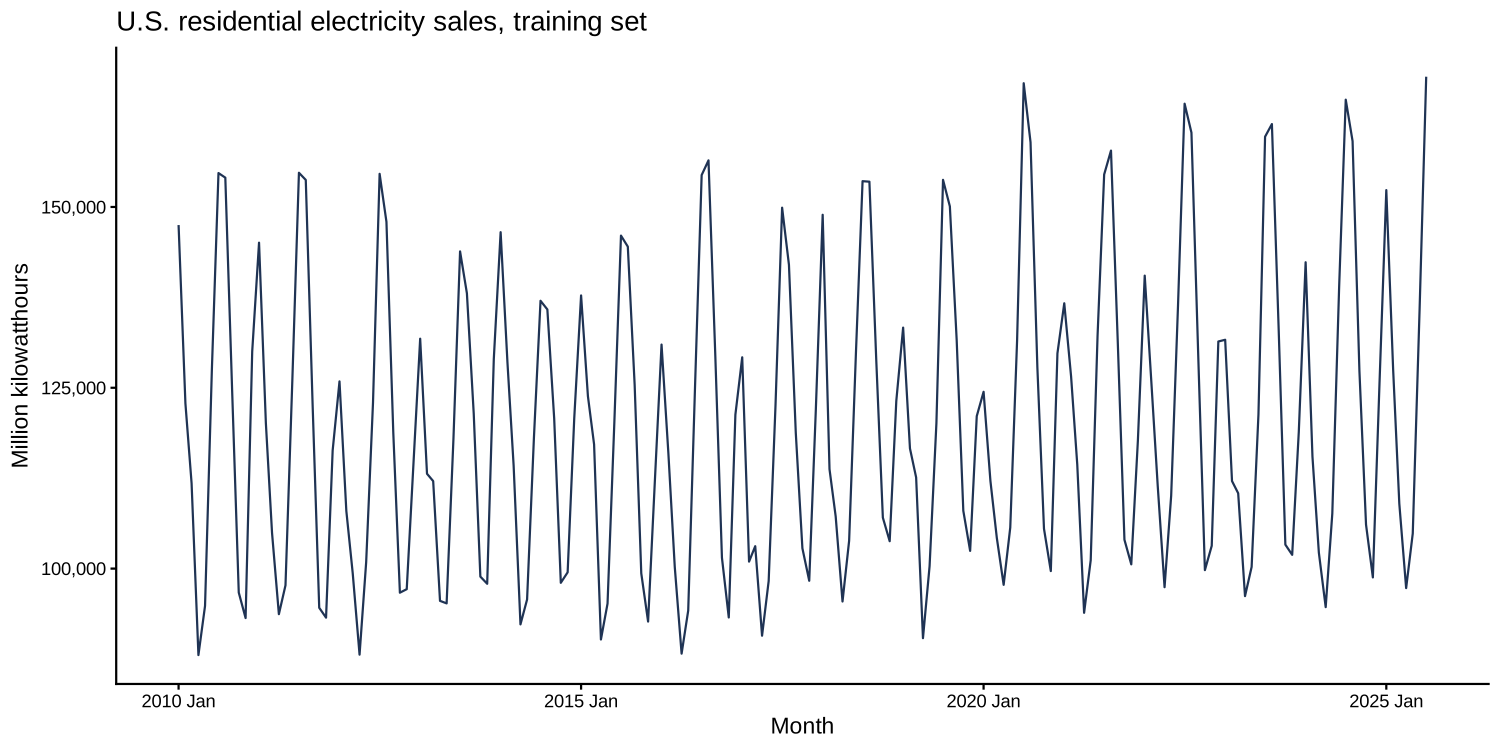

In [4]:
train |>
  autoplot(Sales, colour = "#1F3354") +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "U.S. residential electricity sales, training set",
       x = "Month", y = "Million kilowatthours") +
  theme_classic()

In [5]:
# Average monthly sales for each full year in the training set
train |>
  as_tibble() |>
  filter(year(Month) <= 2024) |>
  group_by(Year = year(Month)) |>
  summarise(avg_monthly_sales = round(mean(Sales)))

Year,avg_monthly_sales
<dbl>,<dbl>
2010,120476
2011,118567
2012,114543
2013,116234
2014,117267
2015,117008
2016,117588
2017,114887
2018,122424


**Why ETS(M,N,M)?**

- **Seasonality (M):** every year has a big summer peak and a smaller winter peak, and those swings got wider as sales grew, so the seasonality is multiplicative.
- **Trend (N):** average monthly sales barely moved over 15 years (about 120,000 million kWh in 2010 and about 124,000 in 2024), so there is no trend term.
- **Errors (M):** multiplicative errors, to match the multiplicative seasonality.

## 4. Fit both models

The manual model fixes the error, trend and season terms. `ETS(Sales)` with no terms lets fable try every combination and keep the one with the lowest AICc.

In [6]:
fit <- train |>
  model(
    manual = ETS(Sales ~ error("M") + trend("N") + season("M")),
    auto   = ETS(Sales)
  )

fit

manual,auto
<model>,<model>
"<ETS(M,N,M)>","<ETS(M,Ad,M)>"


In [7]:
# Smoothing parameters for each model
tidy(fit) |>
  filter(term %in% c("alpha", "beta", "gamma", "phi"))

.model,term,estimate
<chr>,<chr>,<dbl>
manual,alpha,0.2386308111
manual,gamma,0.0001010614
auto,alpha,0.6712273258
auto,beta,0.0001003128
auto,gamma,0.0001020897
auto,phi,0.9797265456


- **Manual ETS(M,N,M):** alpha is about 0.24 and gamma is almost 0, so the level changes slowly and the seasonal shape stays about the same each year.
- **Automatic ETS(M,Ad,M):** the only structural difference is a damped trend. It also ended up with a much higher alpha (about 0.67), so it puts a lot more weight on the most recent months.

## 5. Forecast the test set

In [8]:
fc <- fit |> forecast(h = nrow(test))

plot_forecast <- function(fc_model, title) {
  acc <- accuracy(fc_model, sales)
  intervals <- fc_model |>
    hilo(level = c(80, 95)) |>
    unpack_hilo(c(`80%`, `95%`)) |>
    as_tibble()
  recent <- sales |> filter_index("2022 Jan" ~ .)

  ggplot(mapping = aes(x = Month)) +
    geom_ribbon(data = intervals, aes(ymin = `95%_lower`, ymax = `95%_upper`, fill = "95% interval")) +
    geom_ribbon(data = intervals, aes(ymin = `80%_lower`, ymax = `80%_upper`, fill = "80% interval")) +
    geom_line(data = recent, aes(y = Sales, colour = "Actual")) +
    geom_point(data = test, aes(y = Sales, colour = "Actual"), size = 1) +
    geom_line(data = intervals, aes(y = .mean, colour = "Forecast")) +
    geom_point(data = intervals, aes(y = .mean, colour = "Forecast"), size = 1) +
    geom_vline(xintercept = as.Date(yearmonth("2025 Jul")), linetype = "dashed", colour = "grey40") +
    scale_fill_manual(values = c("95% interval" = "#F5CDB3", "80% interval" = "#E3A277"),
                      breaks = c("95% interval", "80% interval"), name = NULL) +
    scale_colour_manual(values = c(Actual = "#1F3354", Forecast = "#D95F27"), name = NULL) +
    scale_x_yearmonth(breaks = yearmonth(seq(as.Date("2022-01-01"), as.Date("2026-07-01"), by = "6 months")),
                      date_labels = "%Y-%m") +
    scale_y_continuous(labels = scales::comma, breaks = seq(80000, 180000, 20000)) +
    coord_cartesian(ylim = c(80000, 185000)) +
    labs(
      title = title, x = "Month", y = "Million kilowatthours",
      caption = sprintf(
        "U.S. residential electricity sales. Holdout Aug 2025-Jul 2026.  RMSE %s   MAE %s   MAPE %.2f%%",
        scales::comma(acc$RMSE), scales::comma(acc$MAE), acc$MAPE
      )
    ) +
    guides(fill = guide_legend(order = 1), colour = guide_legend(order = 2)) +
    theme_classic(base_size = 13) +
    theme(legend.position = "top", legend.justification = "left",
          plot.caption = element_text(hjust = 0.5, size = 12))
}

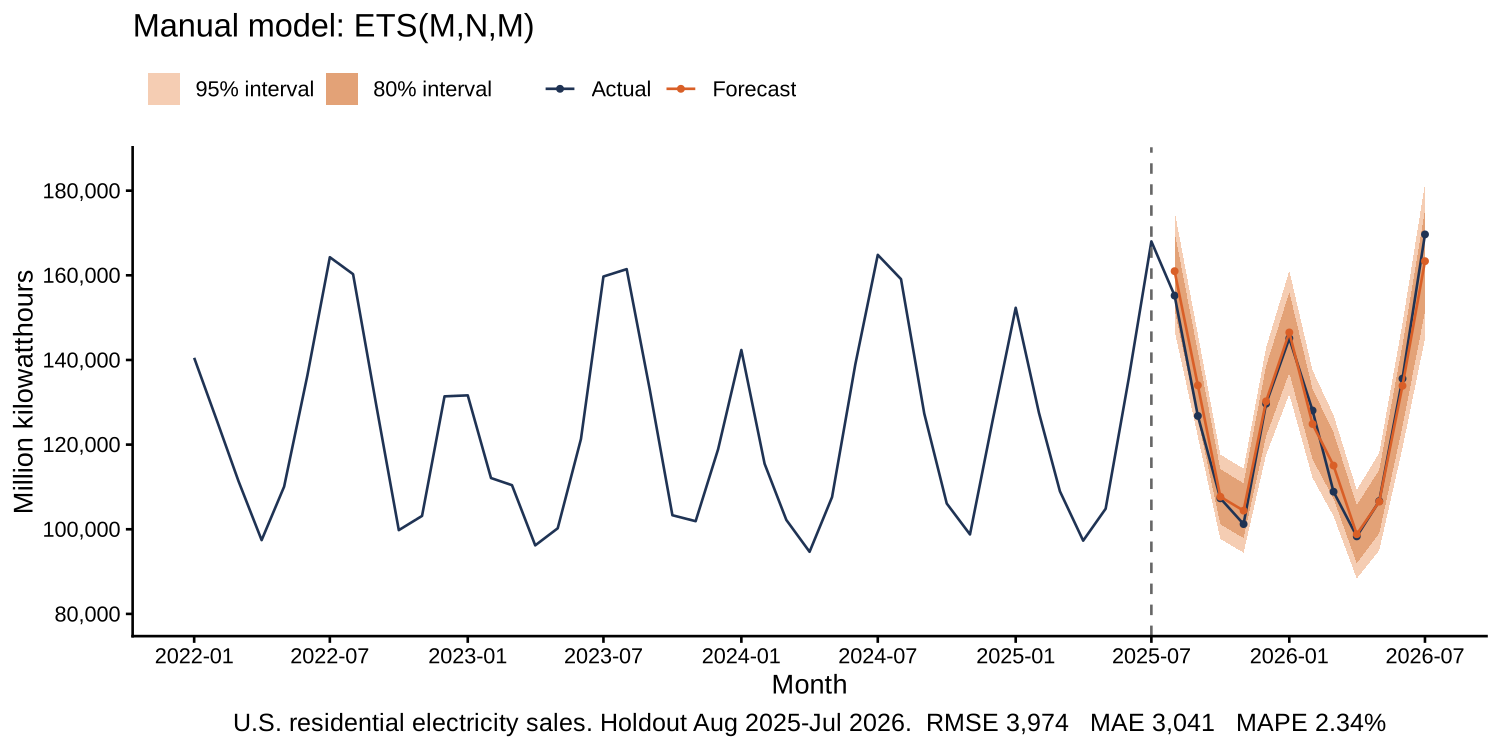

In [9]:
plot_forecast(fc |> filter(.model == "manual"), "Manual model: ETS(M,N,M)")

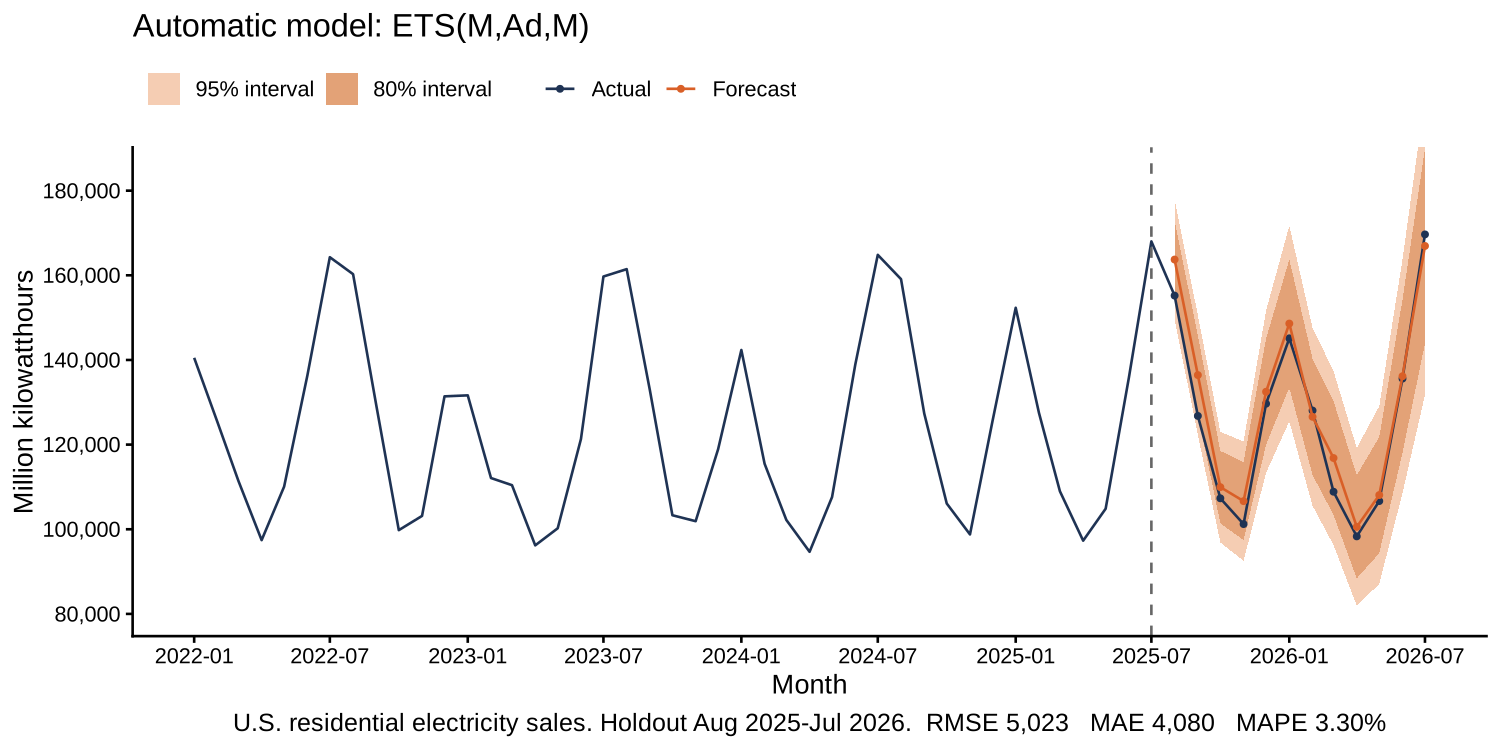

In [10]:
plot_forecast(fc |> filter(.model == "auto"), "Automatic model: ETS(M,Ad,M)")

## 6. Compare the two models

In [11]:
comparison <- glance(fit) |>
  select(.model, AICc) |>
  left_join(accuracy(fc, sales) |> select(.model, RMSE, MAE, MAPE), by = ".model") |>
  mutate(across(where(is.numeric), \(x) round(x, 2)))

comparison

.model,AICc,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
manual,4203.01,3973.91,3041.31,2.34
auto,4199.81,5023.35,4079.85,3.30


**Takeaways**

- **AICc:** the automatic ETS(M,Ad,M) is slightly lower (about 4,199.8 vs 4,203.0), so it fits the training data a little better after the complexity penalty.
- **Holdout accuracy:** the manual ETS(M,N,M) forecasts the test year better on every measure (RMSE about 3,974 vs 5,023, MAE about 3,041 vs 4,080, MAPE 2.34% vs 3.30%).
- **Why:** with its high alpha, the automatic model leans heavily on the last few months of training data, which hurts it over a 12-month horizon. The manual model's steadier level holds up better.

## References

U.S. Energy Information Administration. (2026). *Monthly Energy Review, Table 7.6: Electricity end use* [Data set]. https://www.eia.gov/totalenergy/data/browser/?tbl=T07.06